# Imports

In [46]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
from pathlib import Path
import csv
from scipy.optimize import minimize

# Q1

In [47]:
im = cv2.imread("C:\\EN3160 - Image Processing and Machine Vision\\a-02\\a2images\\a2images\\the_berry_farms_sunflower_field.jpeg",cv2.IMREAD_REDUCED_COLOR_4)
gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
gray = gray.astype(np.float32) / 255.0
print("Image dimensions:", gray.shape)


Image dimensions: (360, 360)


In [48]:

SIGMAS = np.linspace(1.0, 12.0, num=25)
RELATIVE_THRESHOLD = 0.6


In [49]:
responses = []
for sigma in SIGMAS: 
    log_response = gaussian_laplace(gray, sigma=sigma)
    normalized_log = (sigma ** 2) * log_response
    response = np.abs(normalized_log)
    responses.append(response)


In [50]:

scale_space = np.stack(responses, axis=0)
local_max = maximum_filter( scale_space,size=(3, 5,5),mode="nearest")
threshold = RELATIVE_THRESHOLD * float(scale_space.max())
is_extremum = ((scale_space == local_max)& (scale_space >= threshold))
scale_idx, y_idx, x_idx = np.where(is_extremum)

blobs = []
for si, y, x in zip(scale_idx, y_idx, x_idx):
    sigma = float(SIGMAS[si])
    response = float(scale_space[si, y, x])
    radius = np.sqrt(2.0) * sigma
    blobs.append(
        (response, int(x), int(y), sigma, float(radius))
    )
blobs.sort(key=lambda item: item[0], reverse=True)


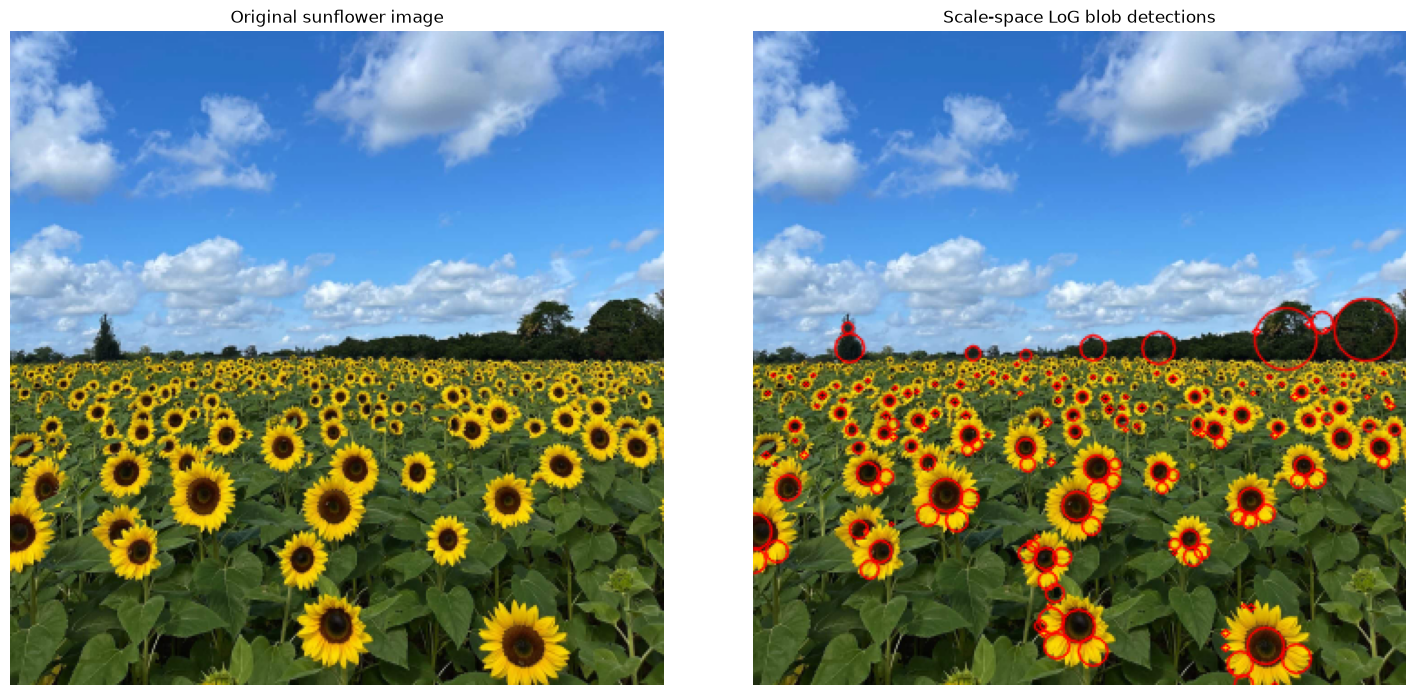

In [51]:


result = im.copy()

for response, x, y, sigma, radius in blobs:
    cv2.circle(
        result,
        (x, y),
        max(1, int(round(radius))),
        (0, 0, 255),
        1,
        cv2.LINE_AA
    )

largest = sorted(
    blobs,
    key=lambda item: item[4],
    reverse=True
)[:10]

# print("\nLargest detected circles")
# print("Rank | x | y | sigma | radius | LoG response")

# for rank, (response, x, y, sigma, radius) in enumerate(
#     largest, start=1
# ):
#     print(
#         f"{rank:4d} | {x:4d} | {y:4d} | "
#         f"{sigma:5.2f} | {radius:6.2f} | "
#         f"{response:.5f}"
#     )

with open("q1_largest_circles.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(
        ["rank", "x", "y", "sigma", "radius_pixels", "log_response"]
    )

    for rank, blob in enumerate(largest, start=1):
        response, x, y, sigma, radius = blob
        writer.writerow(
            [rank, x, y, sigma, radius, response]
        )


result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
original_rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(original_rgb)
axes[0].set_title("Original sunflower image")
axes[0].axis("off")

axes[1].imshow(result_rgb)
axes[1].set_title("Scale-space LoG blob detections")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("q1_log_detection_result.png", dpi=200)
plt.show()

max_response_image = scale_space.max(axis=0)

# plt.figure(figsize=(9, 7))
# plt.imshow(max_response_image, cmap="inferno")
# plt.colorbar(label="Maximum normalized |LoG| response")
# plt.title("Maximum LoG response across scales")
# plt.axis("off")
# plt.tight_layout()
# plt.savefig("q1_log_response.png", dpi=200)
# plt.show()


# Q2

In [52]:

np.random.seed(0)

N = 100
half_n = N // 2

# Ground-truth circle
r_gt = 10
x0_gt, y0_gt = 2, 3
s_circle = r_gt / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = s_circle * np.random.randn(half_n)

x = x0_gt + (r_gt + n) * np.cos(t)
y = y0_gt + (r_gt + n) * np.sin(t)
X_circ = np.column_stack((x, y))

# Ground-truth line: y = mx + b
m_gt, b_gt = -1, 2
s_line = 1.0

x = np.linspace(-12, 12, half_n)
y = m_gt * x + b_gt + s_line * np.random.randn(half_n)
X_line = np.column_stack((x, y))

# Combined point set
X = np.vstack((X_circ, X_line))




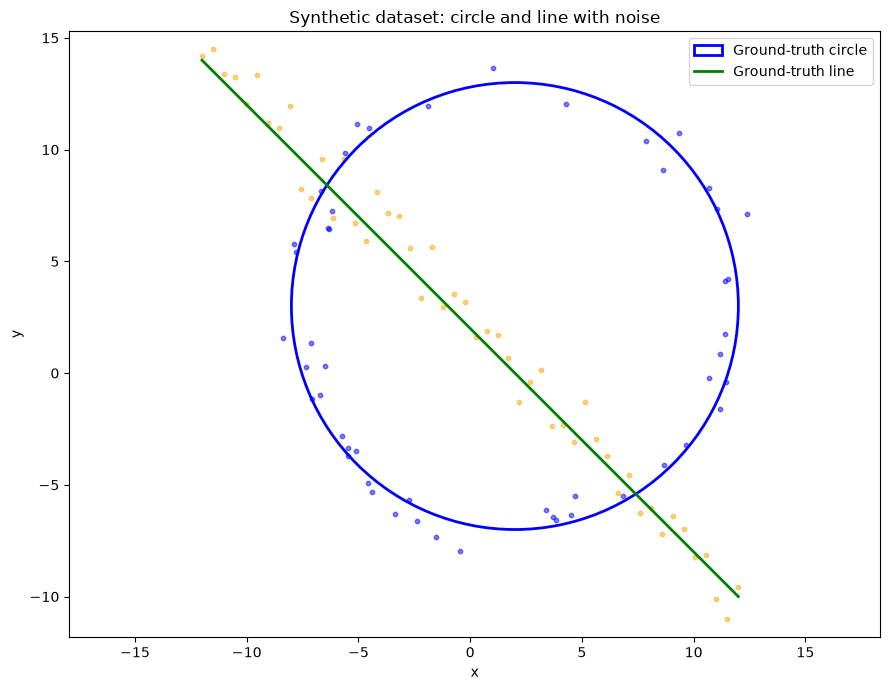

In [53]:
plt.figure(figsize=(9, 7))
plt.scatter(X_line[:, 0], X_line[:, 1], s=10, color="orange", alpha=0.5)
plt.scatter(X_circ[:, 0], X_circ[:, 1], s=10, color="blue", alpha=0.5)
circle = plt.Circle((x0_gt, y0_gt), r_gt, color="blue", fill=False, lw=2, label="Ground-truth circle")
plt.gca().add_artist(circle)
line_x = np.array([-12, 12])
line_y = m_gt * line_x + b_gt
plt.plot(line_x, line_y, color="green", lw=2, label="Ground-truth line")
plt.title("Synthetic dataset: circle and line with noise")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.tight_layout()
plt.legend()
plt.show()



## RANSAC LINE FITTING

In [54]:
def line_from_two_points(p1, p2):
    direction = p2 - p1
    length = np.linalg.norm(direction)
    if length < 1e-10:
        return None
    normal = np.array([-direction[1], direction[0]]) / length
    d = np.dot(normal, p1)
    return normal[0], normal[1], d

def line_distances(points, model):
    a, b, d = model
    return np.abs(a * points[:, 0] + b * points[:, 1] - d)

def ransac_line(points, iterations=3000, threshold=1.8,
                min_inliers=35):
    best_model = None
    best_inliers = None
    best_sample = None

    for _ in range(iterations):
        # A line requires two sample points
        indices = np.random.choice(len(points), 2, replace=False)
        sample = points[indices]

        model = line_from_two_points(sample[0], sample[1])

        if model is None:
            continue

        distances = line_distances(points, model)
        inliers = distances < threshold

        if inliers.sum() >= min_inliers:
            if (best_inliers is None or
                    inliers.sum() > best_inliers.sum()):
                best_model = model
                best_inliers = inliers
                best_sample = sample.copy()

    return best_model, best_inliers, best_sample
line_fit, line_inliers, line_sample = ransac_line(X)
print("Best line model (a, b, d):", line_ransac)
print("Number of inliers:", line_inliers.sum())
print("Unit-normal magnitude:",np.linalg.norm(line_ransac[:2]))



Best line model (a, b, d): (np.float64(0.7060506323381652), np.float64(0.7081613549007578), np.float64(1.6919486446248255))
Number of inliers: 57
Unit-normal magnitude: 1.0


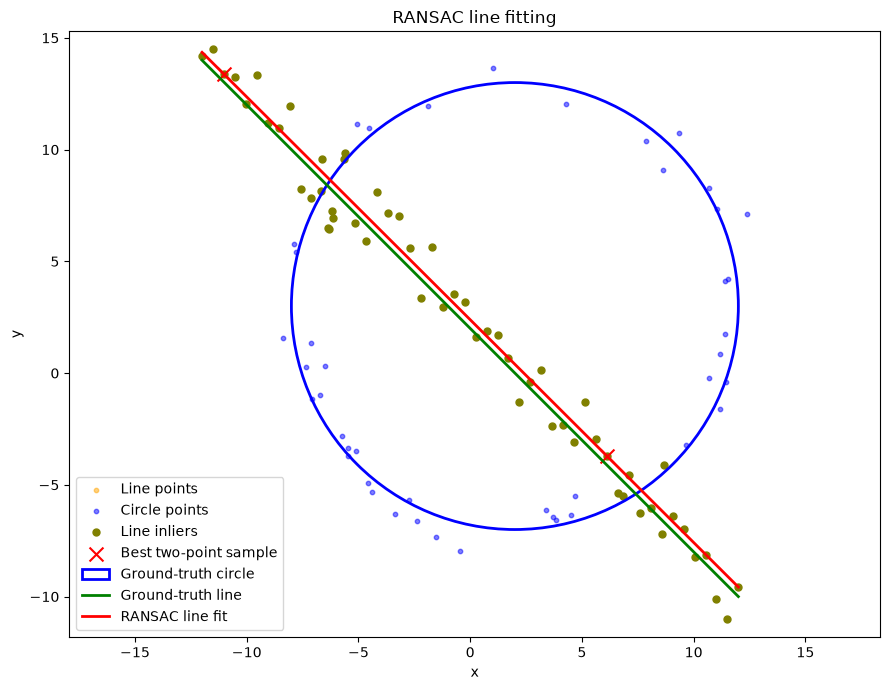

In [55]:

plt.figure(figsize=(9, 7))

plt.scatter(X_line[:, 0], X_line[:, 1],
            s=10, color="orange", alpha=0.5, label="Line points")
plt.scatter(X_circ[:, 0], X_circ[:, 1],
            s=10, color="blue", alpha=0.5, label="Circle points")

plt.scatter(X[line_inliers, 0], X[line_inliers, 1],
            s=25, color="olive", label="Line inliers")

plt.scatter(line_sample[:, 0], line_sample[:, 1],
            s=100, marker="x", color="red",
            label="Best two-point sample")

circle = plt.Circle((x0_gt, y0_gt), r_gt,
                    color="blue", fill=False, lw=2,
                    label="Ground-truth circle")
plt.gca().add_artist(circle)

line_x = np.array([-12, 12])
line_y = m_gt * line_x + b_gt
plt.plot(line_x, line_y, color="green", lw=2,
         label="Ground-truth line")

# Convert ax + by = d to y = mx + c
a, b, d = line_ransac

if abs(b) > 1e-10:
    line_y_ransac = (d - a * line_x) / b
    plt.plot(line_x, line_y_ransac, color="red", lw=2,
             label="RANSAC line fit")
else:
    plt.axvline(d / a, color="red", lw=2,
                label="RANSAC line fit")

plt.title("RANSAC line fitting")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.tight_layout()
plt.legend()
plt.show()


In [56]:

def fit_line_tls(points):
    centroid = points.mean(axis=0)
    centered = points - centroid

    # SVD: smallest singular direction is the line normal
    _, _, vt = np.linalg.svd(centered, full_matrices=False)

    normal = vt[-1]
    normal = normal / np.linalg.norm(normal)
    d = np.dot(normal, centroid)

    return normal[0], normal[1], d


# Refine line using the RANSAC consensus
line_best = fit_line_tls(X[line_inliers])

# Remove line inliers for Question 2(b)
X_remaining = X[~line_inliers]

print("QUESTION 2(a): LINE FITTING")
print("RANSAC line (a, b, d):", line_ransac)
print("Refined TLS line (a, b, d):", line_best)
print("Unit-normal magnitude:",
      np.linalg.norm(line_best[:2]))
print("Number of line inliers:", line_inliers.sum())
print("Points remaining:", len(X_remaining))


QUESTION 2(a): LINE FITTING
RANSAC line (a, b, d): (np.float64(0.7060506323381652), np.float64(0.7081613549007578), np.float64(1.6919486446248255))
Refined TLS line (a, b, d): (np.float64(0.7156488270044808), np.float64(0.6984602754681979), np.float64(1.5617747756951443))
Unit-normal magnitude: 1.0
Number of line inliers: 57
Points remaining: 43


## CIRCLE ESTIMATION FROM THREE POINTS

In [57]:


def circle_from_three_points(points):
    
    p1, p2, p3 = points

    A = 2 * np.array([
        [p2[0] - p1[0], p2[1] - p1[1]],
        [p3[0] - p1[0], p3[1] - p1[1]]
    ])

    rhs = np.array([
        p2 @ p2 - p1 @ p1,
        p3 @ p3 - p1 @ p1
    ])

    if abs(np.linalg.det(A)) < 1e-8:
        return None

    cx, cy = np.linalg.solve(A, rhs)
    radius = np.linalg.norm(p1 - np.array([cx, cy]))

    if not np.isfinite(radius):
        return None

    return cx, cy, radius


def circle_distances(points, model):

    cx, cy, radius = model
    distances = np.linalg.norm(
        points - np.array([cx, cy]), axis=1
    )
    return np.abs(distances - radius)



##RANSAC CIRCLE FITTING

In [58]:

def ransac_circle(points, iterations=5000, threshold=1.2,
                  min_inliers=30):
    best_model = None
    best_inliers = None
    best_sample = None

    if len(points) < 3:
        raise RuntimeError("Not enough points to fit a circle.")

    for _ in range(iterations):
        # Three non-collinear points determine a circle
        indices = np.random.choice(len(points), 3, replace=False)
        sample = points[indices]
        model = circle_from_three_points(sample)
        if model is None:
            continue
        distances = circle_distances(points, model)
        inliers = distances < threshold
        if inliers.sum() >= min_inliers:
            if (best_inliers is None or
                    inliers.sum() > best_inliers.sum()):
                best_model = model
                best_inliers = inliers
                best_sample = sample.copy()

    if best_model is None:
        raise RuntimeError(
            "No acceptable circle consensus found. "
            "Adjust the threshold or minimum consensus."
        )

    return best_model, best_inliers, best_sample


circle_ransac, circle_inliers, circle_sample = ransac_circle(
    X_remaining
)




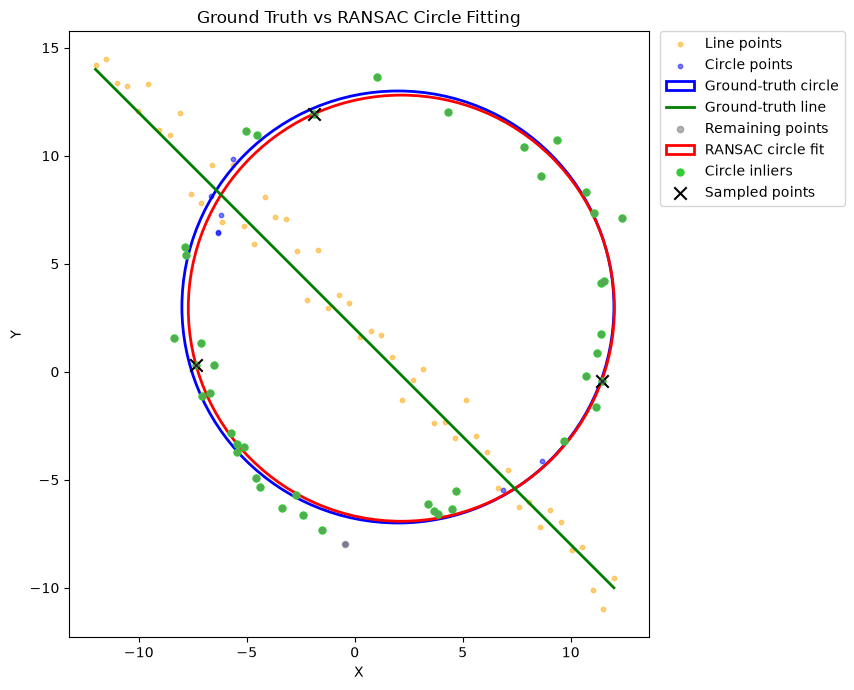

RANSAC circle (cx, cy, radius): (np.float64(2.1590326761762193), np.float64(2.9438434924786905), np.float64(9.863815359872813))
Number of circle inliers: 42
Number of remaining points: 43


In [64]:
fig, ax = plt.subplots(figsize=(9, 7))

# Original line and circle points
ax.scatter(
    X_line[:, 0], X_line[:, 1],
    s=10, color="orange", alpha=0.5,
    label="Line points"
)

ax.scatter(
    X_circ[:, 0], X_circ[:, 1],
    s=10, color="blue", alpha=0.5,
    label="Circle points"
)

# Ground-truth circle
gt_circle = plt.Circle(
    (x0_gt, y0_gt), r_gt,
    color="blue", fill=False, linewidth=2,
    label="Ground-truth circle"
)
ax.add_patch(gt_circle)

# Ground-truth line
line_x = np.array([-12, 12])
line_y = m_gt * line_x + b_gt

ax.plot(
    line_x, line_y,
    color="green", linewidth=2,
    label="Ground-truth line"
)

# Remaining points after line fitting
ax.scatter(
    X_remaining[:, 0], X_remaining[:, 1],
    c="gray", s=20, alpha=0.6,
    label="Remaining points"
)

# RANSAC circle
cx, cy, radius = circle_ransac

ransac_circle_patch = plt.Circle(
    (cx, cy), radius,
    color="red", fill=False, linewidth=2,
    label="RANSAC circle fit"
)
ax.add_patch(ransac_circle_patch)

# Circle inliers
ax.scatter(
    X_remaining[circle_inliers, 0],
    X_remaining[circle_inliers, 1],
    c="limegreen", s=25,
    label="Circle inliers"
)

# Three points used by the best RANSAC sample
ax.scatter(
    circle_sample[:, 0], circle_sample[:, 1],
    c="black", marker="x", s=80,
    label="Sampled points"
)

ax.set_aspect("equal", adjustable="box")
ax.set_title("Ground Truth vs RANSAC Circle Fitting")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)

ax.scatter(
    X_remaining[:, 0],
    X_remaining[:, 1],
    c="gray",
    s=12,
    alpha=0.35,
    label="_nolegend_"
)

plt.tight_layout()
plt.show()
ax.grid(alpha=0.2)


print("RANSAC circle (cx, cy, radius):", circle_ransac)
print("Number of circle inliers:", circle_inliers.sum())
print("Number of remaining points:", len(X_remaining))

In [65]:

from scipy.optimize import minimize

def circle_objective(params, points):
    cx, cy, radius = params

    if radius <= 0:
        return 1e12

    distances = np.linalg.norm(
        points - np.array([cx, cy]), axis=1
    )

    errors = distances - radius

    return np.sum(errors ** 2)


# Initial estimate from RANSAC
initial_circle = np.array(circle_ransac, dtype=float)

# Optimize using circle inliers
result = minimize(
    circle_objective,
    initial_circle,
    args=(X_remaining[circle_inliers],),
    method="Nelder-Mead",
    options={
        "maxiter": 10000,
        "xatol": 1e-9,
        "fatol": 1e-9
    }
)

if not result.success:
    print("Optimization warning:", result.message)

circle_best = result.x

print("QUESTION 2(b): CIRCLE FITTING")
print("RANSAC circle (cx, cy, radius):", circle_ransac)
print("Refined circle (cx, cy, radius):", circle_best)
print("Ground-truth circle:", (x0_gt, y0_gt, r_gt))
print("Number of circle inliers:", circle_inliers.sum())


QUESTION 2(b): CIRCLE FITTING
RANSAC circle (cx, cy, radius): (np.float64(2.1590326761762193), np.float64(2.9438434924786905), np.float64(9.863815359872813))
Refined circle (cx, cy, radius): [1.86852053 3.12615243 9.92984015]
Ground-truth circle: (2, 3, 10)
Number of circle inliers: 42


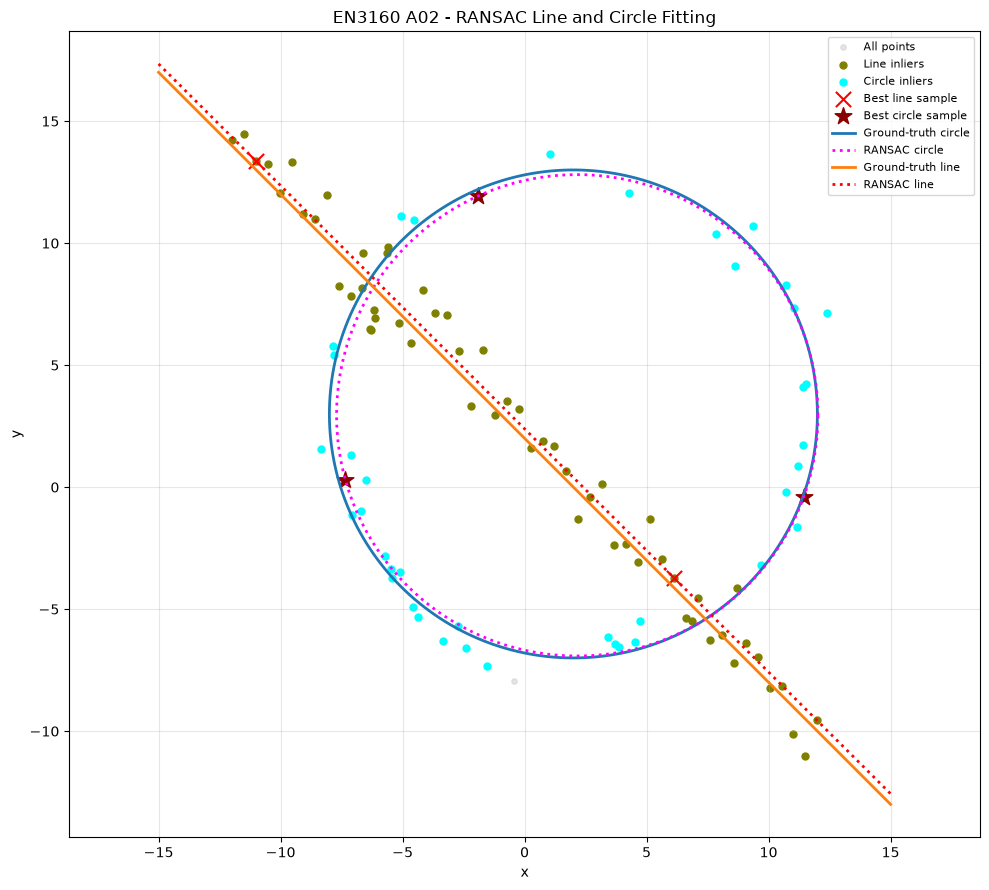

In [68]:

plt.figure(figsize=(10, 9))

# All original points
plt.scatter(X[:, 0], X[:, 1], s=15, color="lightgray",
            alpha=0.6, label="All points")

# Line inliers
plt.scatter(X[line_inliers, 0], X[line_inliers, 1],
            s=25, color="olive", label="Line inliers")

# Circle inliers
circle_points = X_remaining[circle_inliers]
plt.scatter(circle_points[:, 0], circle_points[:, 1],
            s=25, color="cyan", label="Circle inliers")

# Best samples
plt.scatter(line_sample[:, 0], line_sample[:, 1],
            marker="x", s=120, color="red",
            label="Best line sample")

plt.scatter(circle_sample[:, 0], circle_sample[:, 1],
            marker="*", s=160, color="darkred",
            label="Best circle sample")

# Ground-truth circle
theta = np.linspace(0, 2 * np.pi, 500)

plt.plot(
    x0_gt + r_gt * np.cos(theta),
    y0_gt + r_gt * np.sin(theta),
     linewidth=2, label="Ground-truth circle"
)

# RANSAC circle
cx, cy, radius = circle_ransac
plt.plot(
    cx + radius * np.cos(theta),
    cy + radius * np.sin(theta),
    color="magenta", linestyle=":", linewidth=2,
    label="RANSAC circle"
)


# Ground-truth line
line_x = np.array([-15, 15])
plt.plot(line_x, m_gt * line_x + b_gt,
          linewidth=2, label="Ground-truth line")

# RANSAC line
a, b, d = line_ransac
if abs(b) > 1e-10:
    plt.plot(line_x, (d - a * line_x) / b,
             color="red", linestyle=":", linewidth=2,
             label="RANSAC line")



plt.title("EN3160 A02 - RANSAC Line and Circle Fitting")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig("q2_ransac_results.png", dpi=300)
plt.show()


### Question 2(d): What happens if we fit the circle first?

If we fit the circle first, RANSAC can identify the circle by selecting three points and finding the model with the largest consensus. However, some points belonging to the line may also fall within the circle's radial error threshold and be incorrectly classified as circle inliers.

After removing the circle inliers, the remaining points can be used to estimate the line using RANSAC. However, if too many line points are incorrectly classified as circle inliers, the line estimation may become less accurate or fail to obtain the required consensus.

Therefore, the order of fitting can affect the results because the RANSAC thresholds and consensus sets determine which points are assigned to each model.

# Q3